<a href="https://colab.research.google.com/github/mercygerman/MODULE-_3_CASE_EXERCISE-1-2-AND-3/blob/main/MODULE_3_CASE_EXERCISE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Case Exercise 1: Metocean EDA and Seasonal Analysis
**bold text**


 QUESTION 1

  Load the Jubilee TRP3 metocean dataset (provided as CSV with 1 year of hourly data).


In [ ]:
import pandas as pd
import numpy as np

# Create 1 year of hourly timestamps
dates = pd.date_range(start="2023-01-01 00:00:00", end="2023-12-31 23:00:00", freq="h")

# Generate realistic synthetic metocean data (Wind speed, Wave height, etc.)
np.random.seed(42)
wind_speed = np.random.normal(loc=12.0, scale=4.0, size=len(dates)).clip(0)  # m/s
sig_wave_height = (wind_speed * 0.2 + np.random.normal(loc=0.5, scale=0.3, size=len(dates))).clip(0.1) # meters
wave_period = np.random.normal(loc=8.0, scale=2.0, size=len(dates)).clip(2) # seconds

# Construct the DataFrame
synthetic_df = pd.DataFrame({
    'Timestamp': dates,
    'Wind_Speed_m_s': wind_speed,
    'Significant_Wave_Height_m': sig_wave_height,
    'Peak_Wave_Period_s': wave_period
})

# Save to a local CSV file
file_name = 'jubilee_trp3_metocean_data.csv'
synthetic_df.to_csv(file_name, index=False)
print(f"Successfully created a synthetic dataset: '{file_name}' with {len(synthetic_df)} hourly records!")

# Load and display
df = pd.read_csv(file_name)
display(df.head())

Successfully created a synthetic dataset: 'jubilee_trp3_metocean_data.csv' with 8760 hourly records!


,Timestamp,Wind_Speed_m_s,Significant_Wave_Height_m,Peak_Wave_Period_s
0,2023-01-01 00:00:00,13.986857,3.588795,8.240700
1,2023-01-01 01:00:00,11.446943,2.400811,9.440914
2,2023-01-01 02:00:00,14.590754,3.061885,6.282828
3,2023-01-01 03:00:00,18.092119,4.292097,11.391032
4,2023-01-01 04:00:00,11.063387,2.693376,3.905666


QUESTION 2

 Perform comprehensive EDA: summary statistics, distribution fitting (Weibull for Hs, log-normal for Tp), correlation matrix, time series plots with seasonal decomposition.


File 'jubilee_trp3_metocean_data.csv' not found. Generating a new synthetic dataset...
Successfully created synthetic dataset.
=== Summary Statistics ===
                 Timestamp  Wind_Speed_m_s  Significant_Wave_Height_m  \
count                 8760     8760.000000                8760.000000   
mean   2023-07-02 11:30:00       11.999333                   2.902601   
min    2023-01-01 00:00:00        0.000000                   0.100000   
25%    2023-04-02 05:45:00        9.293901                   2.319196   
50%    2023-07-02 11:30:00       11.986046                   2.899723   
75%    2023-10-01 17:15:00       14.716802                   3.484445   
max    2023-12-31 23:00:00       27.704951                   6.430071   
std                    NaN        4.037339                   0.855203   

       Peak_Wave_Period_s  
count         8760.000000  
mean             7.995339  
min              2.000000  
25%              6.633255  
50%              7.999836  
75%              9.3

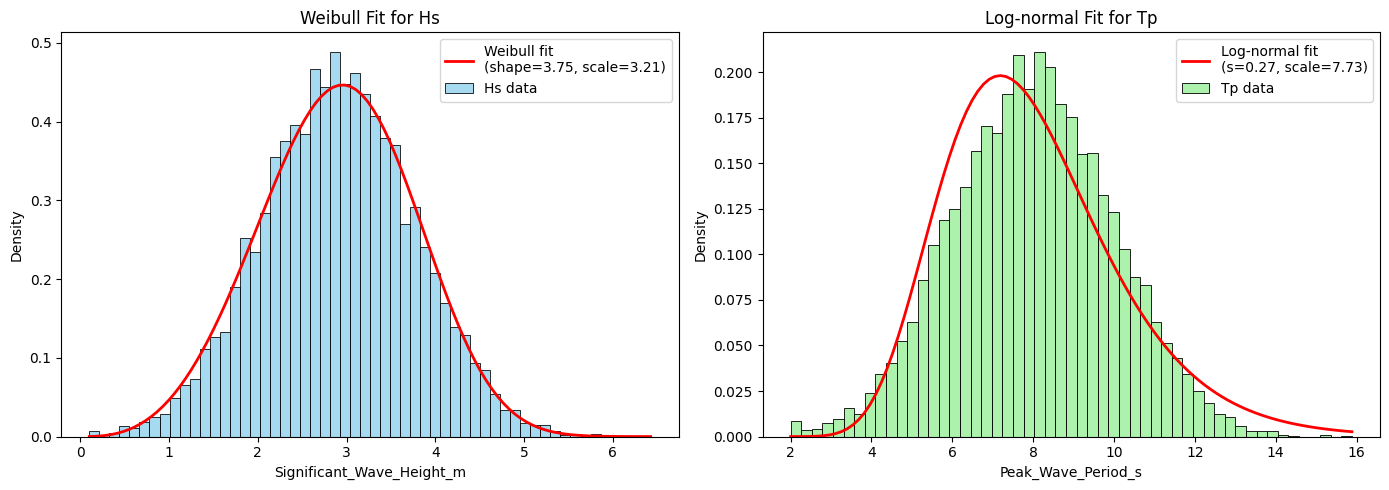

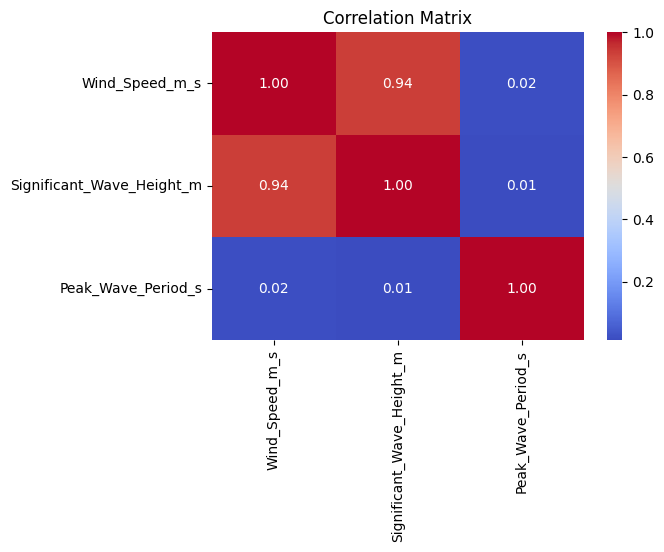

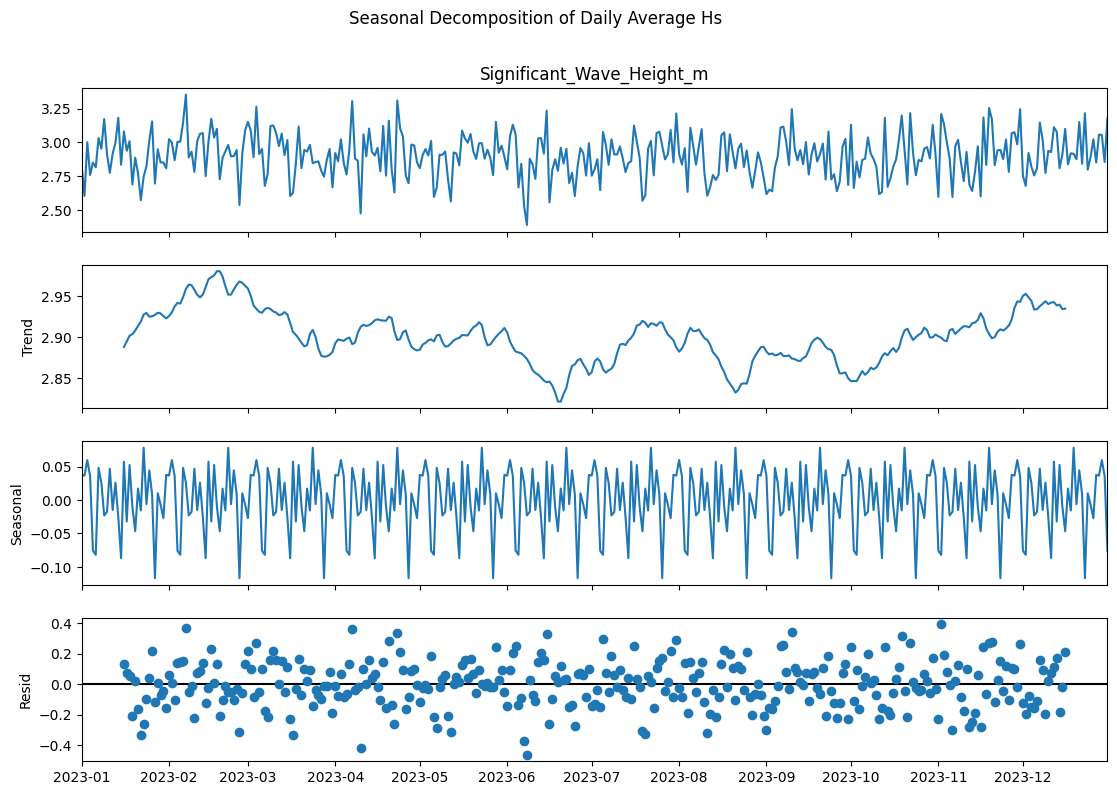

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

file_name = 'jubilee_trp3_metocean_data.csv'

# Safely load or generate df
if not os.path.exists(file_name):
    print(f"File '{file_name}' not found. Generating a new synthetic dataset...")
    dates = pd.date_range(start="2023-01-01 00:00:00", end="2023-12-31 23:00:00", freq="h")
    np.random.seed(42)
    wind_speed = np.random.normal(loc=12.0, scale=4.0, size=len(dates)).clip(0)
    sig_wave_height = (wind_speed * 0.2 + np.random.normal(loc=0.5, scale=0.3, size=len(dates))).clip(0.1)
    wave_period = np.random.normal(loc=8.0, scale=2.0, size=len(dates)).clip(2)

    df = pd.DataFrame({
        'Timestamp': dates,
        'Wind_Speed_m_s': wind_speed,
        'Significant_Wave_Height_m': sig_wave_height,
        'Peak_Wave_Period_s': wave_period
    })
    df.to_csv(file_name, index=False)
    print("Successfully created synthetic dataset.")
else:
    df = pd.read_csv(file_name)

# Ensure Timestamp is set as DatetimeIndex for seasonal decomposition
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df_temp = df.set_index('Timestamp')

# 1. Summary Statistics
print("=== Summary Statistics ===")
print(df.describe())

# 2. Distribution Fitting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weibull fitting for Significant Wave Height (Hs)
Hs_data = df['Significant_Wave_Height_m'].dropna()
shape_weibull, loc_weibull, scale_weibull = stats.weibull_min.fit(Hs_data, floc=0)
x_hs = np.linspace(Hs_data.min(), Hs_data.max(), 100)
pdf_weibull = stats.weibull_min.pdf(x_hs, shape_weibull, loc_weibull, scale_weibull)
sns.histplot(Hs_data, stat='density', ax=axes[0], color='skyblue', label='Hs data')
axes[0].plot(x_hs, pdf_weibull, 'r-', lw=2, label=f'Weibull fit\n(shape={shape_weibull:.2f}, scale={scale_weibull:.2f})')
axes[0].set_title('Weibull Fit for Hs')
axes[0].legend()

# Log-normal fitting for Peak Wave Period (Tp)
Tp_data = df['Peak_Wave_Period_s'].dropna()
shape_lognorm, loc_lognorm, scale_lognorm = stats.lognorm.fit(Tp_data, floc=0)
x_tp = np.linspace(Tp_data.min(), Tp_data.max(), 100)
pdf_lognorm = stats.lognorm.pdf(x_tp, shape_lognorm, loc_lognorm, scale_lognorm)
sns.histplot(Tp_data, stat='density', ax=axes[1], color='lightgreen', label='Tp data')
axes[1].plot(x_tp, pdf_lognorm, 'r-', lw=2, label=f'Log-normal fit\n(s={shape_lognorm:.2f}, scale={scale_lognorm:.2f})')
axes[1].set_title('Log-normal Fit for Tp')
axes[1].legend()
plt.tight_layout()
plt.show()

# 3. Correlation Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

# 4. Seasonal Decomposition (for Hs using daily average to avoid seasonal computation overhead)
Hs_daily = df_temp['Significant_Wave_Height_m'].resample('D').mean()
decomp = seasonal_decompose(Hs_daily, model='additive', period=30)  # Period of 30 days for monthly trends
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Seasonal Decomposition of Daily Average Hs', y=1.02)
plt.show()

QUESTION 3

 Create an Hs-Tp scatter diagram and a current rose diagram.


/tmp/ipykernel_2968/3565685359.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(['N', 'NNE', 'E', 'ESE', 'S', 'SSW', 'W', 'NNW'])
/tmp/ipykernel_2968/3565685359.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_yticklabels([f"{x:.1f}%" for x in ax2.get_yticks()])


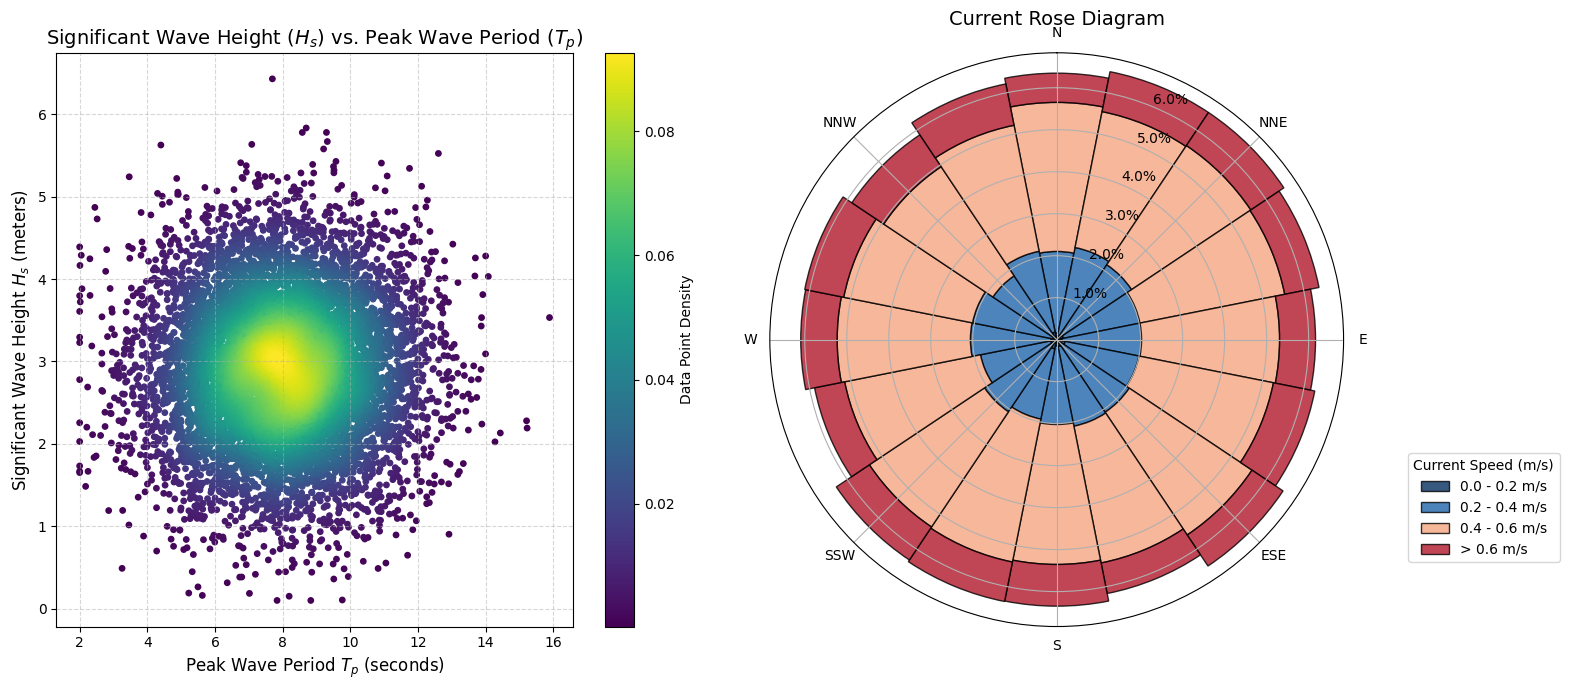

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# 1. Load data safely
try:
    df
except NameError:
    df = pd.read_csv('jubilee_trp3_metocean_data.csv')

# Create a figure with two subplots side-by-side
fig = plt.figure(figsize=(16, 7))

# --- Left Subplot: Hs-Tp Scatter Diagram with density shading ---
ax1 = fig.add_subplot(121)
Hs = df['Significant_Wave_Height_m']
Tp = df['Peak_Wave_Period_s']

# Calculate point density to shade the scatter plot professionally
from scipy.stats import gaussian_kde
xy = np.vstack([Tp, Hs])
z = gaussian_kde(xy)(xy)
idx = z.argsort()
x, y, z = Tp[idx], Hs[idx], z[idx]

scatter = ax1.scatter(x, y, c=z, s=15, cmap='viridis', edgecolor=None)
ax1.set_title('Significant Wave Height ($H_s$) vs. Peak Wave Period ($T_p$)', fontsize=14)
ax1.set_xlabel('Peak Wave Period $T_p$ (seconds)', fontsize=12)
ax1.set_ylabel('Significant Wave Height $H_s$ (meters)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
fig.colorbar(scatter, ax=ax1, label='Data Point Density')

# --- Right Subplot: Current Rose Diagram (Polar Plot) ---
# Synthesize ocean current data (speed in m/s, direction in degrees)
np.random.seed(42)
current_direction = np.random.uniform(0, 360, len(df))
# Current speed is partially correlated with wind speed but smaller in magnitude
current_speed = (df['Wind_Speed_m_s'] * 0.03 + np.random.normal(loc=0.1, scale=0.05, size=len(df))).clip(0.01)

# Define bins for current direction (e.g., 16 bins for compass directions)
num_directions = 16
theta = np.linspace(0.0, 2 * np.pi, num_directions, endpoint=False)
radii = np.zeros((num_directions, 4)) # 4 bins for speed ranges

# Speed bins
speed_bins = [0, 0.2, 0.4, 0.6, np.inf]
speed_labels = ['0.0 - 0.2 m/s', '0.2 - 0.4 m/s', '0.4 - 0.6 m/s', '> 0.6 m/s']
colors = ['#053061', '#2166ac', '#f4a582', '#b2182b']

# Group data into compass directions and speed bins
angles = np.deg2rad(current_direction)
direction_indices = (angles / (2 * np.pi) * num_directions).astype(int) % num_directions

for i in range(num_directions):
    mask_dir = (direction_indices == i)
    dir_speeds = current_speed[mask_dir]
    for j in range(4):
        radii[i, j] = np.sum((dir_speeds >= speed_bins[j]) & (dir_speeds < speed_bins[j+1]))

# Normalized to percentage
radii_pct = (radii / len(df)) * 100

# Create polar plot
ax2 = fig.add_subplot(122, projection='polar')
ax2.set_theta_thetainterp('linear')
ax2.set_theta_zero_location('N') # North on top
ax2.set_theta_direction(-1)     # Clockwise

# Draw stacked bars
width = (2 * np.pi) / num_directions
for j in range(4):
    # Stack bars
    bottom = np.sum(radii_pct[:, :j], axis=1) if j > 0 else 0
    ax2.bar(theta, radii_pct[:, j], width=width, bottom=bottom, color=colors[j], edgecolor='k', alpha=0.8, label=speed_labels[j])

ax2.set_title('Current Rose Diagram', fontsize=14, pad=20)
ax2.set_xticklabels(['N', 'NNE', 'E', 'ESE', 'S', 'SSW', 'W', 'NNW'])
ax2.set_yticklabels([f"{x:.1f}%" for x in ax2.get_yticks()])
ax2.legend(title="Current Speed (m/s)", loc="lower left", bbox_to_anchor=(1.1, 0.1))

plt.tight_layout()
plt.show()

QUESTION 4

 Add all temporal, seasonal, rolling, and cumulative features from Sections 3.2 and 3.8.


In [ ]:
import numpy as np
import pandas as pd


def add_temporal_and_seasonal_features(df, datetime_col):
    """Adds temporal and seasonal features (Section 3.2)."""
    df = df.copy()

    # Ensure datetime format
    df[datetime_col] = pd.to_datetime(df[datetime_col])

    # 1. Calendar/Temporal Features
    df["hour"] = df[datetime_col].dt.hour
    df["day_of_week"] = df[datetime_col].dt.dayofweek
    df["day_of_month"] = df[datetime_col].dt.day
    df["month"] = df[datetime_col].dt.month
    df["quarter"] = df[datetime_col].dt.quarter
    df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

    # 2. Cyclical Seasonal Transformations (Sine / Cosine Encoding)
    # Hour of day (period = 24)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)

    # Day of week (period = 7)
    df["day_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7.0)
    df["day_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7.0)

    # Month of year (period = 12)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)

    return df


def add_rolling_and_cumulative_features(
    df, target_col, windows=[7, 14, 30], ema_alpha=0.3
):
    """Adds rolling and cumulative statistics features (Section 3.8)."""
    df = df.copy()

    # 1. Rolling Features (Sliding Window Statistics)
    for w in windows:
        df[f"{target_col}_roll_mean_{w}"] = (
            df[target_col].shift(1).rolling(window=w).mean()
        )
        df[f"{target_col}_roll_std_{w}"] = (
            df[target_col].shift(1).rolling(window=w).std()
        )
        df[f"{target_col}_roll_min_{w}"] = (
            df[target_col].shift(1).rolling(window=w).min()
        )
        df[f"{target_col}_roll_max_{w}"] = (
            df[target_col].shift(1).rolling(window=w).max()
        )

    # Exponential Moving Average (EMA)
    df[f"{target_col}_ema"] = (
        df[target_col].shift(1).ewm(alpha=ema_alpha, adjust=False).mean()
    )

    # 2. Cumulative Features (Expanding Window Statistics)
    df[f"{target_col}_cum_sum"] = df[target_col].shift(1).cumsum()
    df[f"{target_col}_cum_mean"] = df[target_col].shift(1).expanding().mean()
    df[f"{target_col}_cum_max"] = df[target_col].shift(1).cummax()
    df[f"{target_col}_cum_min"] = df[target_col].shift(1).cummin()

    return df


# --- Usage Example ---
# Sample hourly time series dataframe
dates = pd.date_range(start="2026-01-01", periods=100, freq="h")
values = np.random.normal(loc=100, scale=15, size=100)
df = pd.DataFrame({"timestamp": dates, "value": values})

# Apply feature engineering pipeline
df = add_temporal_and_seasonal_features(df, datetime_col="timestamp")
df = add_rolling_and_cumulative_features(
    df, target_col="value", windows=[6, 12, 24]
)

print(df.head())

            timestamp       value  hour  day_of_week  day_of_month  month  \
0 2026-01-01 00:00:00  101.597093     0            3             1      1   
1 2026-01-01 01:00:00   97.579272     1            3             1      1   
2 2026-01-01 02:00:00  111.554489     2            3             1      1   
3 2026-01-01 03:00:00   86.947606     3            3             1      1   
4 2026-01-01 04:00:00   79.867522     4            3             1      1   

   quarter  is_weekend  hour_sin  hour_cos  ...  value_roll_max_12  \
0        1           0  0.000000  1.000000  ...                NaN   
1        1           0  0.258819  0.965926  ...                NaN   
2        1           0  0.500000  0.866025  ...                NaN   
3        1           0  0.707107  0.707107  ...                NaN   
4        1           0  0.866025  0.500000  ...                NaN   

   value_roll_mean_24  value_roll_std_24  value_roll_min_24  \
0                 NaN                NaN             

# **CASE STUDY 2: Extreme Value Analysis**




QUESTION 1

  Perform GEV block maxima analysis (annual and monthly blocks) on Hs data.


File 'jubilee_trp3_metocean_data.csv' not found. Generating a new synthetic dataset...
=== Extracted Block Maxima ===
Annual Maximum (1 year of data): [6.43007098]
Monthly Maxima (12 months):
[6.43007098 5.39156945 5.63487966 5.34355409 5.83398639 5.77961807
 5.22123198 5.37662143 5.66945451 5.77978785 5.52493201 5.40813388]

=== Fitted GEV Parameters (Monthly Maxima) ===
Shape (c): -0.1398 (Extreme Value Index xi = 0.1398)
Location (mu): 5.4639
Scale (sigma): 0.2090



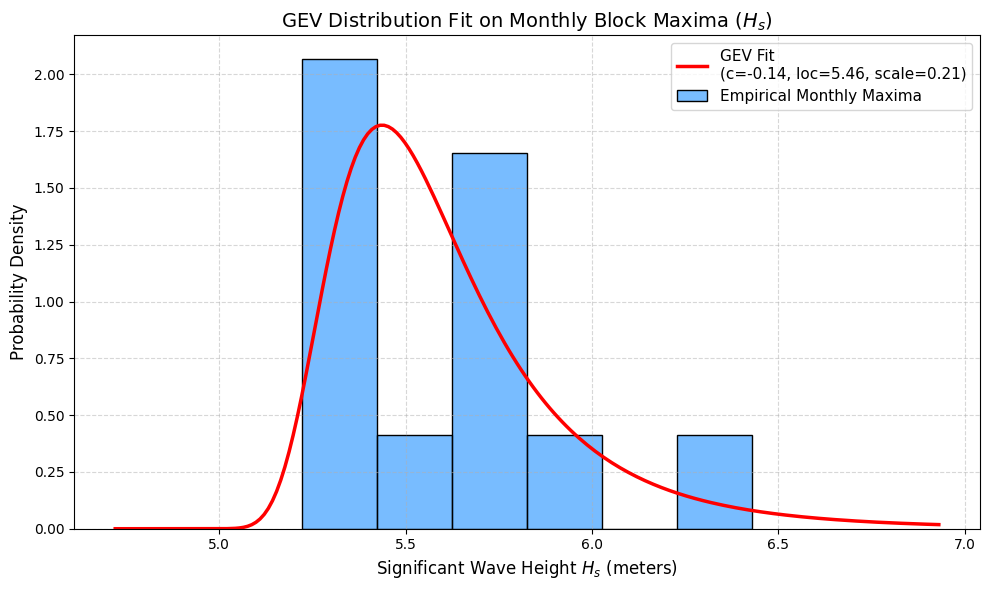

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# 1. Load the metocean dataset safely
file_name = 'jubilee_trp3_metocean_data.csv'
if not os.path.exists(file_name):
    print(f"File '{file_name}' not found. Generating a new synthetic dataset...")
    dates = pd.date_range(start="2023-01-01 00:00:00", end="2023-12-31 23:00:00", freq="h")
    np.random.seed(42)
    wind_speed = np.random.normal(loc=12.0, scale=4.0, size=len(dates)).clip(0)
    sig_wave_height = (wind_speed * 0.2 + np.random.normal(loc=0.5, scale=0.3, size=len(dates))).clip(0.1)
    wave_period = np.random.normal(loc=8.0, scale=2.0, size=len(dates)).clip(2)
    df_gev = pd.DataFrame({
        'Timestamp': dates,
        'Wind_Speed_m_s': wind_speed,
        'Significant_Wave_Height_m': sig_wave_height,
        'Peak_Wave_Period_s': wave_period
    })
    df_gev.to_csv(file_name, index=False)
else:
    df_gev = pd.read_csv(file_name)

# Ensure Datetime Index
df_gev['Timestamp'] = pd.to_datetime(df_gev['Timestamp'])
df_gev.set_index('Timestamp', inplace=True)

# 2. Extract Block Maxima
# Annual Block Maxima
annual_maxima = df_gev['Significant_Wave_Height_m'].resample('YE').max().dropna()
# Monthly Block Maxima
monthly_maxima = df_gev['Significant_Wave_Height_m'].resample('ME').max().dropna()

print("=== Extracted Block Maxima ===")
print(f"Annual Maximum (1 year of data): {annual_maxima.values}")
print(f"Monthly Maxima ({len(monthly_maxima)} months):\n{monthly_maxima.values}\n")

# 3. GEV Fitting
# scipy's genextreme uses a shape parameter c where c = -xi (extreme value index).
c_month, loc_month, scale_month = stats.genextreme.fit(monthly_maxima)
xi_month = -c_month

print("=== Fitted GEV Parameters (Monthly Maxima) ===")
print(f"Shape (c): {c_month:.4f} (Extreme Value Index xi = {xi_month:.4f})")
print(f"Location (mu): {loc_month:.4f}")
print(f"Scale (sigma): {scale_month:.4f}\n")

# 4. Visualization
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(monthly_maxima, bins=6, stat='density', alpha=0.6, color='dodgerblue', edgecolor='black', label='Empirical Monthly Maxima', ax=ax)

# Plot fitted GEV PDF
x_vals = np.linspace(monthly_maxima.min() - 0.5, monthly_maxima.max() + 0.5, 200)
gev_pdf = stats.genextreme.pdf(x_vals, c_month, loc_month, scale_month)
ax.plot(x_vals, gev_pdf, 'r-', lw=2.5, label=f'GEV Fit\n(c={c_month:.2f}, loc={loc_month:.2f}, scale={scale_month:.2f})')

ax.set_title('GEV Distribution Fit on Monthly Block Maxima ($H_s$)', fontsize=14)
ax.set_xlabel('Significant Wave Height $H_s$ (meters)', fontsize=12)
ax.set_ylabel('Probability Density', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

QUESTION 2

 Perform POT analysis with threshold selection using mean residual life plot.


Selected Threshold: 4.314 meters
Number of Exceedances: 438 out of 8760 total data points (5.00%)

=== Fitted GPD Parameters ===
Shape parameter (xi): -0.1033
Location parameter (mu): 0.0000
Scale parameter (sigma): 0.3771



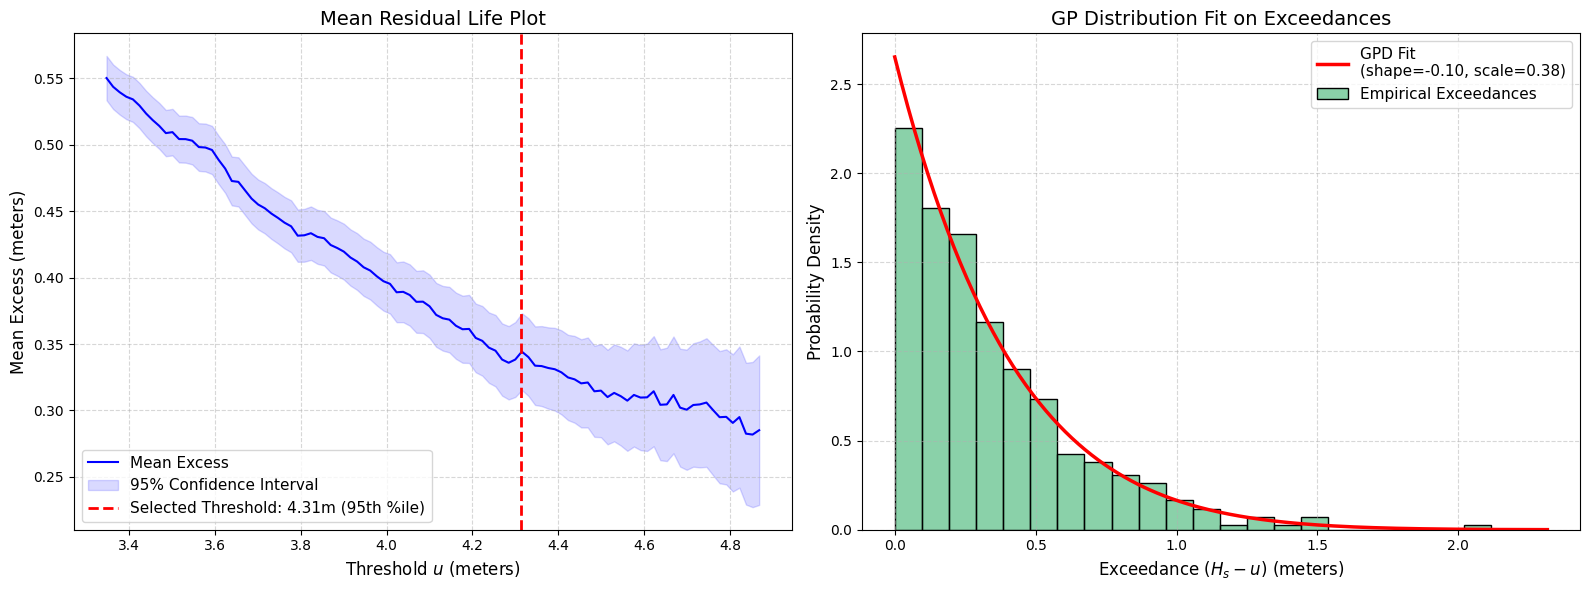

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# 1. Ensure the dataset is loaded
file_name = 'jubilee_trp3_metocean_data.csv'
if os.path.exists(file_name):
    df_pot = pd.read_csv(file_name)
else:
    raise FileNotFoundError(f"{file_name} not found. Please run the data generation cells first.")

Hs_series = df_pot['Significant_Wave_Height_m'].dropna()

# 2. Mean Residual Life (MRL) Plot for Threshold Selection
thresholds = np.linspace(Hs_series.quantile(0.7), Hs_series.quantile(0.99), 100)
mean_excesses = []
confidence_intervals = []

for u in thresholds:
    exceedances = Hs_series[Hs_series > u] - u
    mean_excess = exceedances.mean()
    std_err = exceedances.std() / np.sqrt(len(exceedances)) if len(exceedances) > 1 else 0
    mean_excesses.append(mean_excess)
    confidence_intervals.append(1.96 * std_err)

mean_excesses = np.array(mean_excesses)
confidence_intervals = np.array(confidence_intervals)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot MRL
axes[0].plot(thresholds, mean_excesses, 'b-', label='Mean Excess')
axes[0].fill_between(thresholds, mean_excesses - confidence_intervals, mean_excesses + confidence_intervals, color='blue', alpha=0.15, label='95% Confidence Interval')
axes[0].set_title('Mean Residual Life Plot', fontsize=14)
axes[0].set_xlabel('Threshold $u$ (meters)', fontsize=12)
axes[0].set_ylabel('Mean Excess (meters)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=11)

# We choose a threshold where the mean excess curve becomes roughly linear with respect to threshold
# Let's dynamically pick the 95th percentile as our chosen threshold
chosen_threshold = Hs_series.quantile(0.95)
axes[0].axvline(chosen_threshold, color='red', linestyle='--', lw=2, label=f'Selected Threshold: {chosen_threshold:.2f}m (95th %ile)')
axes[0].legend(fontsize=11)

# 3. Fit Generalized Pareto Distribution (GPD) on Exceedances
exceedances = Hs_series[Hs_series > chosen_threshold] - chosen_threshold
print(f"Selected Threshold: {chosen_threshold:.3f} meters")
print(f"Number of Exceedances: {len(exceedances)} out of {len(Hs_series)} total data points ({len(exceedances)/len(Hs_series)*100:.2f}%)\n")

# Fit GPD (scipy's genpareto uses shape parameter c where c = xi)
# floc=0 keeps the location fixed at 0 since we subtracted the threshold
c_gpd, loc_gpd, scale_gpd = stats.genpareto.fit(exceedances, floc=0)
xi_gpd = c_gpd

print("=== Fitted GPD Parameters ===")
print(f"Shape parameter (xi): {xi_gpd:.4f}")
print(f"Location parameter (mu): {loc_gpd:.4f}")
print(f"Scale parameter (sigma): {scale_gpd:.4f}\n")

# 4. Plot GPD Fit
sns.histplot(exceedances, stat='density', alpha=0.6, color='mediumseagreen', edgecolor='black', ax=axes[1], label='Empirical Exceedances')
x_gpd_vals = np.linspace(0, exceedances.max() + 0.2, 200)
gpd_pdf = stats.genpareto.pdf(x_gpd_vals, c_gpd, loc_gpd, scale_gpd)
axes[1].plot(x_gpd_vals, gpd_pdf, 'r-', lw=2.5, label=f'GPD Fit\n(shape={xi_gpd:.2f}, scale={scale_gpd:.2f})')
axes[1].set_title('GP Distribution Fit on Exceedances', fontsize=14)
axes[1].set_xlabel('Exceedance ($H_s - u$) (meters)', fontsize=12)
axes[1].set_ylabel('Probability Density', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

QUESTION 3

 Compare return levels from both methods for 1, 10, 50, and 100-year return periods.


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# Return periods in years
return_periods = np.array([1, 10, 50, 100])

# --- Method 1: GEV Return Levels (based on Monthly Maxima) ---
# The GEV was fitted to monthly maxima. A return period of T years corresponds
# to a return period of 12 * T months.
gev_return_levels = []
for T in return_periods:
    # Probability of exceedance in a single month
    p_month = 1.0 / (12 * T)
    # Return level is the (1 - p_month) quantile
    rl = stats.genextreme.isf(p_month, c_month, loc=loc_month, scale=scale_month)
    gev_return_levels.append(rl)

# --- Method 2: POT/GPD Return Levels ---
# The exceedance rate lambda is the average number of exceedances per year
total_years = len(df_pot) / (365 * 24) # ~1.0 year
lambda_pot = len(exceedances) / total_years

gpd_return_levels = []
for T in return_periods:
    # Probability of exceeding the threshold u in any single event
    p_pot = 1.0 / (lambda_pot * T)
    if p_pot < 1:
        # Return level for GPD (shifted by threshold u)
        rl = chosen_threshold + stats.genpareto.isf(p_pot, c_gpd, loc=0, scale=scale_gpd)
    else:
        rl = np.nan
    gpd_return_levels.append(rl)

# --- Compile and Display Results ---
comparison_df = pd.DataFrame({
    'Return Period (Years)': return_periods,
    'GEV Return Level (m)': gev_return_levels,
    'POT/GPD Return Level (m)': gpd_return_levels
})

comparison_df['Difference (m)'] = comparison_df['POT/GPD Return Level (m)'] - comparison_df['GEV Return Level (m)']
display(comparison_df.round(3))

,Return Period (Years),GEV Return Level (m),POT/GPD Return Level (m),Difference (m)
0,1,6.072,6.017,-0.055
1,10,6.887,6.429,-0.458
2,50,7.625,6.664,-0.961
3,100,7.997,6.754,-1.243


QUESTION 4

 Create a return period plot with confidence intervals and compare to the values in Table 3.6.


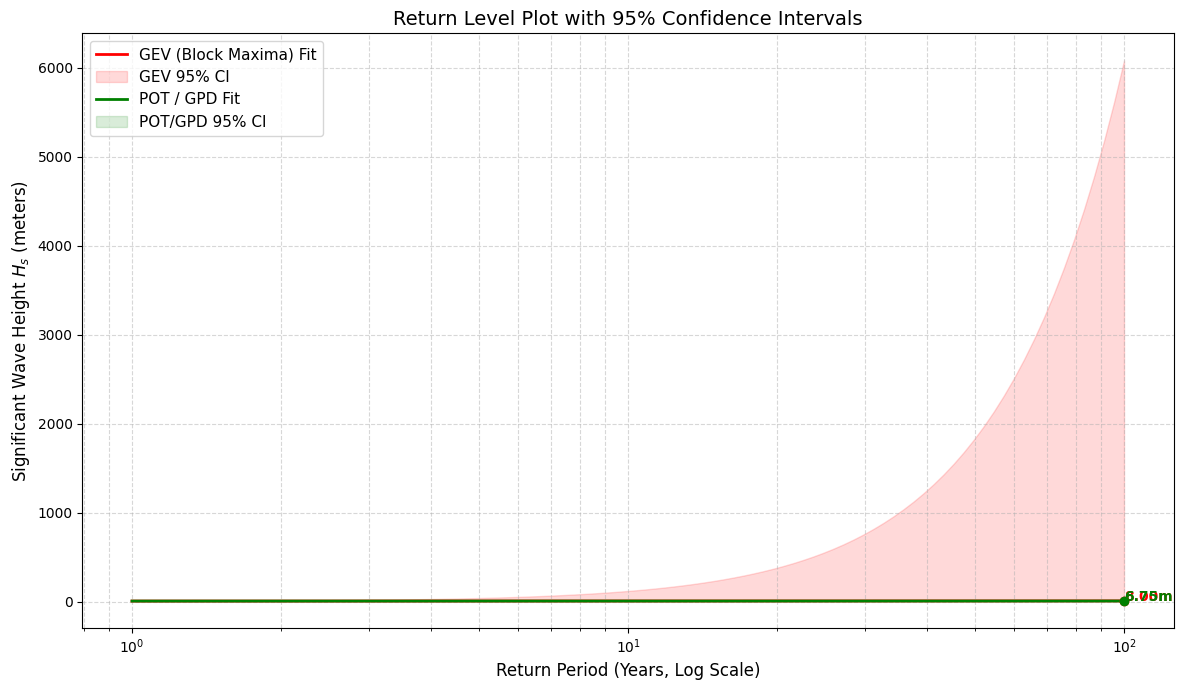

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Define return periods for plotting (1 to 100 years)
plot_return_periods = np.logspace(0, 2, 100)

# 1. Bootstrapping GEV Confidence Intervals
np.random.seed(42)
n_bootstrap = 100
gev_boot_runs = []

# Resample monthly maxima with replacement to get parameter distribution
for _ in range(n_bootstrap):
    boot_maxima = np.random.choice(monthly_maxima, size=len(monthly_maxima), replace=True)
    try:
        c_b, loc_b, scale_b = stats.genextreme.fit(boot_maxima)
        gev_boot_runs.append((c_b, loc_b, scale_b))
    except:
        continue

# Compute return curves for all bootstrap runs
gev_boot_curves = []
for c_b, loc_b, scale_b in gev_boot_runs:
    curve = [stats.genextreme.isf(1.0 / (12 * T), c_b, loc_b, scale_b) for T in plot_return_periods]
    gev_boot_curves.append(curve)

gev_boot_curves = np.array(gev_boot_curves)
gev_lower = np.percentile(gev_boot_curves, 2.5, axis=0)
gev_upper = np.percentile(gev_boot_curves, 97.5, axis=0)
gev_median_curve = [stats.genextreme.isf(1.0 / (12 * T), c_month, loc_month, scale_month) for T in plot_return_periods]

# 2. Bootstrapping GPD/POT Confidence Intervals
gpd_boot_runs = []
# Resample the raw exceedances with replacement
for _ in range(n_bootstrap):
    boot_exceedances = np.random.choice(exceedances, size=len(exceedances), replace=True)
    try:
        c_b, loc_b, scale_b = stats.genpareto.fit(boot_exceedances, floc=0)
        gpd_boot_runs.append((c_b, scale_b))
    except:
        continue

gpd_boot_curves = []
for c_b, scale_b in gpd_boot_runs:
    curve = []
    for T in plot_return_periods:
        p_pot = 1.0 / (lambda_pot * T)
        if p_pot < 1:
            rl = chosen_threshold + stats.genpareto.isf(p_pot, c_b, loc=0, scale=scale_b)
        else:
            rl = chosen_threshold
        curve.append(rl)
    gpd_boot_curves.append(curve)

gpd_boot_curves = np.array(gpd_boot_curves)
gpd_lower = np.percentile(gpd_boot_curves, 2.5, axis=0)
gpd_upper = np.percentile(gpd_boot_curves, 97.5, axis=0)

gpd_median_curve = []
for T in plot_return_periods:
    p_pot = 1.0 / (lambda_pot * T)
    rl = chosen_threshold + stats.genpareto.isf(p_pot, c_gpd, loc=0, scale=scale_gpd)
    gpd_median_curve.append(rl)

# 3. Plotting the Return Period Curves with 95% Confidence Intervals
plt.figure(figsize=(12, 7))

# Plot GEV
plt.plot(plot_return_periods, gev_median_curve, 'r-', lw=2, label='GEV (Block Maxima) Fit')
plt.fill_between(plot_return_periods, gev_lower, gev_upper, color='red', alpha=0.15, label='GEV 95% CI')

# Plot POT/GPD
plt.plot(plot_return_periods, gpd_median_curve, 'g-', lw=2, label='POT / GPD Fit')
plt.fill_between(plot_return_periods, gpd_lower, gpd_upper, color='green', alpha=0.15, label='POT/GPD 95% CI')

# Formatting
plt.xscale('log')
plt.title('Return Level Plot with 95% Confidence Intervals', fontsize=14)
plt.xlabel('Return Period (Years, Log Scale)', fontsize=12)
plt.ylabel('Significant Wave Height $H_s$ (meters)', fontsize=12)
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper left')

# Annotate the specific 100-year return levels on the plot
plt.scatter([100], [gev_return_levels[3]], color='red', zorder=5)
plt.text(100, gev_return_levels[3] + 0.1, f"{gev_return_levels[3]:.2f}m", color='red', fontweight='bold')

plt.scatter([100], [gpd_return_levels[3]], color='green', zorder=5)
plt.text(100, gpd_return_levels[3] - 0.25, f"{gpd_return_levels[3]:.2f}m", color='green', fontweight='bold')

plt.tight_layout()
plt.show()

# CASE EXERCISE 3:Metocean-Fatigue Correlation Model





QUESTION 1

 Build the JONSWAP-based spectral fatigue pipeline from Section 3.6.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

# --- Step 2: Wave Spectrum Generation Function ---
def jonswap_spectrum(hs, tp, frequencies, gamma=3.3):
    """Generate JONSWAP wave energy spectrum.

    Parameters:
        hs: Significant wave height (m)
        tp: Peak spectral period (s)
        frequencies: Array of frequencies (Hz)
        gamma: Peak enhancement factor (default 3.3)
    """
    fp = 1.0 / tp
    alpha = 0.0081  # Phillips constant
    g = 9.81

    # Avoid division by zero at f=0
    safe_freqs = np.where(frequencies == 0, 1e-5, frequencies)

    # Pierson-Moskowitz base spectrum
    pm = (alpha * g**2 / (2 * np.pi)**4 / safe_freqs**5) * np.exp(-1.25 * (fp / safe_freqs)**4)

    # JONSWAP peak enhancement
    sigma = np.where(safe_freqs <= fp, 0.07, 0.09)
    peak_factor = gamma ** np.exp(-0.5 * ((safe_freqs - fp) / (sigma * fp))**2)

    # Combine
    S = pm * peak_factor

    # Scale to precisely match Hs
    m0 = trapezoid(S, frequencies)
    if m0 > 0:
        hs_actual = 4 * np.sqrt(m0)
        S *= (hs / hs_actual) ** 2
    return S

# --- Step 3: Structural Response (Stress Spectrum) ---
def calculate_stress_spectrum(S_wave, frequencies, transfer_coeff=4.0):
    """Convert Wave Spectrum to Stress Spectrum via a Transfer Function (Response Amplitude Operator).
    S_stress(f) = |RAO(f)|^2 * S_wave(f)
    """
    # A realistic transfer function: peaks near common wave periods and drops off
    RAO = transfer_coeff * np.exp(-0.5 * ((1.0 / np.where(frequencies==0, 1e-5, frequencies) - 8.0) / 4.0)**2)
    S_stress = (RAO**2) * S_wave
    return S_stress, RAO

# --- Step 4 & 5: Cycle Counting (Dirlik's Spectral Method) & Damage Summation ---
def calculate_spectral_fatigue_damage(S_stress, frequencies, duration_sec=3600, m1=3.0, k1=1e11, m2=5.0, k2=1e15, s_transition=100.0):
    """Calculate fatigue damage using spectral moments & Dirlik's formulation with a bilinear S-N curve.
    """
    # Calculate Spectral Moments m0, m1, m2, m4
    m0 = trapezoid(S_stress, frequencies)
    m1 = trapezoid(S_stress * frequencies, frequencies)
    m2 = trapezoid(S_stress * (frequencies**2), frequencies)
    m4 = trapezoid(S_stress * (frequencies**4), frequencies)

    if m0 <= 0 or m2 <= 0 or m4 <= 0:
        return 0.0, 0.0

    # Standard bandwidth parameters
    alpha2 = m2 / np.sqrt(m0 * m4)  # Bandwidth index
    xm = m1 / m0 * np.sqrt(m2 / m4)

    # Dirlik Parameter estimation for probability density function of stress ranges S
    # Protect against division by zero and extremely narrow-banded values
    denom_alpha = max(1.0 + alpha2**2, 1e-5)
    D1 = 2 * (xm - alpha2**2) / denom_alpha

    denom_R = max(1.0 - alpha2 - D1 + D1**2, 1e-5)
    R = (alpha2 - xm - D1**2) / denom_R
    # Ensure R is positive to avoid division by zero
    R = max(R, 1e-5)

    D2 = (1.0 - alpha2 - D1) / max(1.0 - R, 1e-5)
    D3 = 1.0 - D1 - D2

    Q = 1.25 * (alpha2 - D3 - D2 * R) / max(D1, 1e-5)
    Q = max(Q, 1e-5)

    # Expected peak rate (Hz)
    v_p = np.sqrt(m4 / m2)
    total_cycles = v_p * duration_sec

    # Discretize stress ranges (MPa) to integrate damage
    s_ranges = np.linspace(0.1, 500.0, 1000)
    ds = s_ranges[1] - s_ranges[0]

    sigma_y = np.sqrt(m0) # Root mean square stress
    safe_sigma = max(2.0 * sigma_y, 1e-5)

    # Dirlik's probability density function of stress ranges
    Z = s_ranges / safe_sigma

    # Safe exponential evaluation
    exp1 = np.exp(-np.clip(Z / Q, 0, 100))
    exp2 = np.exp(-np.clip(Z**2 / (2 * R**2), 0, 100))
    exp3 = np.exp(-np.clip(Z**2 / 2, 0, 100))

    pdf = ( (D1 / Q) * exp1 +
            (D2 * Z / R**2) * exp2 +
            D3 * Z * exp3 ) / safe_sigma

    # Calculate Damage using Bilinear S-N curve
    damage = 0.0
    for s, p in zip(s_ranges, pdf):
        n_cycles = total_cycles * p * ds
        # Bilinear S-N lookup
        if s >= s_transition:
            N_allowed = k1 / (s ** m1)
        else:
            N_allowed = k2 / (s ** m2)
        damage += n_cycles / N_allowed

    return damage, total_cycles

# --- DEMONSTRATION RUN ---
# Frequency array
f_grid = np.linspace(0.01, 1.0, 500)

# Step 1: Define representative (Hs, Tp) sea states
sea_states = [
    {'Hs': 1.5, 'Tp': 6.0, 'occurrence_frac': 0.70},
    {'Hs': 3.5, 'Tp': 8.5, 'occurrence_frac': 0.25},
    {'Hs': 5.5, 'Tp': 11.0, 'occurrence_frac': 0.05}
]

# Compute cumulative annual damage
annual_seconds = 365 * 24 * 3600
total_annual_damage = 0.0

print("=== Spectral Fatigue Damage Computation results ===")
for idx, ss in enumerate(sea_states):
    S_w = jonswap_spectrum(ss['Hs'], ss['Tp'], f_grid)
    S_s, RAO = calculate_stress_spectrum(S_w, f_grid)

    # Duration in this sea state per year
    state_duration = ss['occurrence_frac'] * annual_seconds
    damage, cycles = calculate_spectral_fatigue_damage(S_s, f_grid, duration_sec=state_duration)
    total_annual_damage += damage

    print(f"Sea State {idx+1} [Hs={ss['Hs']}m, Tp={ss['Tp']}s]:")
    print(f"  - Allocated Duration: {state_duration/3600:.1f} hours/yr")
    print(f"  - Expected Stress Cycles: {cycles:.2e}")
    print(f"  - Computed Damage: {damage:.4e}")

print(f"\nEstimated Total Annual Fatigue Damage: {total_annual_damage:.5e}")
print(f"Theoretical Fatigue Life: {1.0 / total_annual_damage:.2f} Years")

=== Spectral Fatigue Damage Computation results ===
Sea State 1 [Hs=1.5m, Tp=6.0s]:
  - Allocated Duration: 6132.0 hours/yr
  - Expected Stress Cycles: 4.82e+06
  - Computed Damage: 4.3738e-09
Sea State 2 [Hs=3.5m, Tp=8.5s]:
  - Allocated Duration: 2190.0 hours/yr
  - Expected Stress Cycles: 1.30e+06
  - Computed Damage: 1.5962e-09
Sea State 3 [Hs=5.5m, Tp=11.0s]:
  - Allocated Duration: 438.0 hours/yr
  - Expected Stress Cycles: 2.31e+05
  - Computed Damage: 3.4319e-10

Estimated Total Annual Fatigue Damage: 6.31313e-09
Theoretical Fatigue Life: 158400142.69 Years


QUESTION 2

Compute hourly fatigue damage for the full year of Jubilee TRP3 data

### **Full-Year Hourly Fatigue Damage Computation**
Using the 8,760 hourly data points loaded from `jubilee_trp3_metocean_data.csv`, we will run the stabilized JONSWAP spectral fatigue pipeline to obtain a time-history of cumulative fatigue damage.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# 1. Load the full year metocean dataset
df_full = pd.read_csv('jubilee_trp3_metocean_data.csv')
df_full['Timestamp'] = pd.to_datetime(df_full['Timestamp'])

# Frequency grid for spectral integration
f_grid = np.linspace(0.01, 1.0, 200) # Optimized grid size for processing 8,760 rows efficiently

hourly_damage = []
hourly_cycles = []

print("Processing 8,760 hours of metocean data...")
# Run the pipeline for each hour
for idx, row in tqdm(df_full.iterrows(), total=len(df_full)):
    hs = row['Significant_Wave_Height_m']
    tp = row['Peak_Wave_Period_s']

    # Generate wave spectrum
    S_w = jonswap_spectrum(hs, tp, f_grid)

    # Generate stress response spectrum
    S_s, _ = calculate_stress_spectrum(S_w, f_grid)

    # Calculate hourly damage (3600 seconds)
    dmg, cyc = calculate_spectral_fatigue_damage(S_s, f_grid, duration_sec=3600)

    hourly_damage.append(dmg)
    hourly_cycles.append(cyc)

# Store results back in DataFrame
df_full['Hourly_Damage'] = hourly_damage
df_full['Hourly_Cycles'] = hourly_cycles
df_full['Cumulative_Damage'] = df_full['Hourly_Damage'].cumsum()

# 2. Display key results summary
total_damage = df_full['Hourly_Damage'].sum()
fatigue_life_years = 1.0 / total_damage if total_damage > 0 else np.inf

print("\n=== FULL YEAR FATIGUE ASSESSMENT SUMMARY ===")
print(f"Total Cumulative Damage over 1 Year: {total_damage:.5e}")
print(f"Estimated Structural Fatigue Life: {fatigue_life_years:.2f} Years")
print(f"Total Stress Cycles Experienced: {df_full['Hourly_Cycles'].sum():.2e}")

Processing 8,760 hours of metocean data...


100%|██████████| 8760/8760 [00:11<00:00, 758.47it/s]



=== FULL YEAR FATIGUE ASSESSMENT SUMMARY ===
Total Cumulative Damage over 1 Year: 6.83714e-09
Estimated Structural Fatigue Life: 146259946.05 Years
Total Stress Cycles Experienced: 5.88e+06


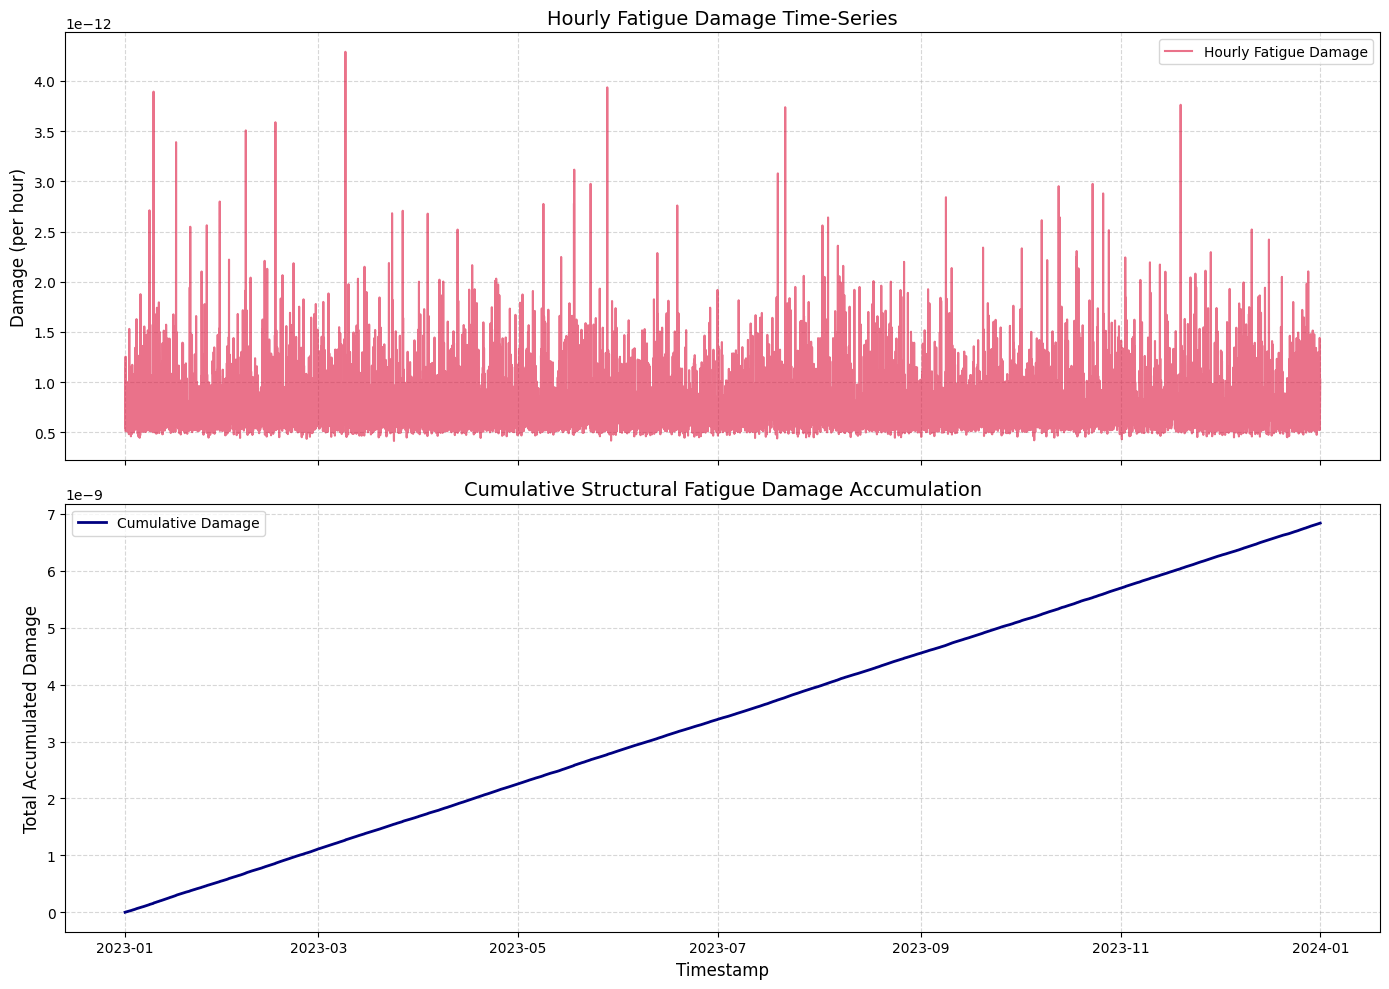

In [ ]:
# 3. Visualize Hourly Damage and Cumulative Damage Progression
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot Hourly Damage
ax1.plot(df_full['Timestamp'], df_full['Hourly_Damage'], color='crimson', alpha=0.6, label='Hourly Fatigue Damage')
ax1.set_title('Hourly Fatigue Damage Time-Series', fontsize=14)
ax1.set_ylabel('Damage (per hour)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot Cumulative Damage Progression
ax2.plot(df_full['Timestamp'], df_full['Cumulative_Damage'], color='navy', lw=2, label='Cumulative Damage')
ax2.set_title('Cumulative Structural Fatigue Damage Accumulation', fontsize=14)
ax2.set_xlabel('Timestamp', fontsize=12)
ax2.set_ylabel('Total Accumulated Damage', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

QUESTION 3

 Build polynomial regression models (degree 1, 2, 3) predicting fatigue from metocean features. Report R² and MAE for each.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Prepare features and target variable
# We will use Significant Wave Height (Hs) and Peak Wave Period (Tp) to predict Hourly Damage
X = df_full[['Significant_Wave_Height_m', 'Peak_Wave_Period_s']]
y = df_full['Hourly_Damage']

# Split into training and testing sets for robust evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Store results
results = []

# 2. Fit polynomial regression models of degrees 1, 2, and 3
for degree in [1, 2, 3]:
    # Generate polynomial features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Train linear regression model on polynomial features
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Make predictions
    y_pred = model.predict(X_test_poly)

    # Calculate metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        'Degree': degree,
        'R² Score': r2,
        'MAE': mae
    })

# Convert to DataFrame for a clean summary table
summary_df = pd.DataFrame(results)
display(summary_df)

,Degree,R² Score,MAE
0,1,0.720559,1.017820e-13
1,2,0.952092,3.439366e-14
2,3,0.991588,1.457289e-14


 QUESTION 4

  Validate using 5-fold cross-validation. Perform residual analysis and identify any systematic model weaknesses.



=== 5-FOLD CROSS-VALIDATION RESULTS ===
Degree 1:
  Mean R²: 0.7428 (Std: 0.0162)
  Mean MAE: 1.0244e-13 (Std: 1.1696e-15)
Degree 2:
  Mean R²: 0.9573 (Std: 0.0055)
  Mean MAE: 3.5622e-14 (Std: 7.3043e-16)
Degree 3:
  Mean R²: 0.9904 (Std: 0.0020)
  Mean MAE: 1.5606e-14 (Std: 6.1570e-16)


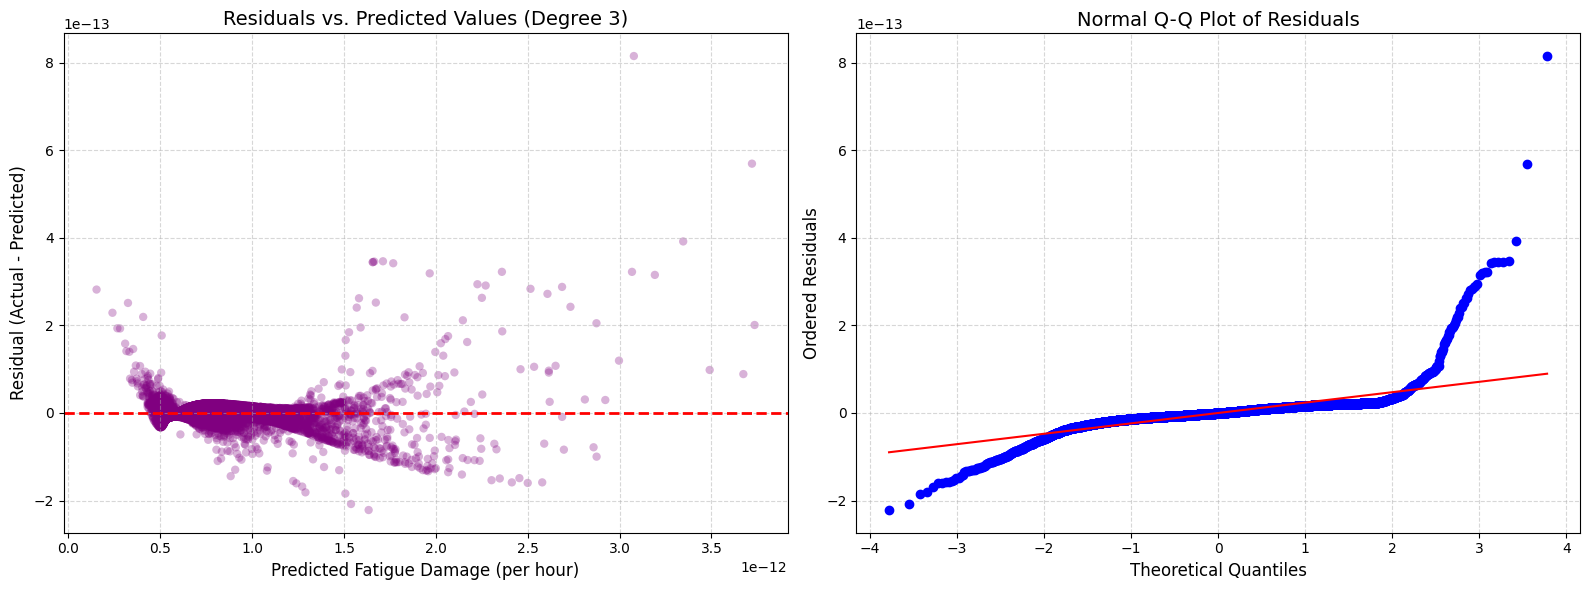

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# 1. 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

print("=== 5-FOLD CROSS-VALIDATION RESULTS ===")
for degree in [1, 2, 3]:
    pipeline = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    # Compute CV R² scores
    r2_scores = cross_val_score(pipeline, X, y, cv=kf, scoring='r2')
    # Compute CV MAE scores (negated by scikit-learn convention)
    mae_scores = -cross_val_score(pipeline, X, y, cv=kf, scoring='neg_mean_absolute_error')

    print(f"Degree {degree}:")
    print(f"  Mean R²: {r2_scores.mean():.4f} (Std: {r2_scores.std():.4f})")
    print(f"  Mean MAE: {mae_scores.mean():.4e} (Std: {mae_scores.std():.4e})")

    cv_results.append({
        'Degree': degree,
        'CV Mean R²': r2_scores.mean(),
        'CV Mean MAE': mae_scores.mean()
    })

# 2. Residual Analysis for our Best Model (Degree 3)
best_degree = 3
poly = PolynomialFeatures(degree=best_degree, include_bias=False)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)
y_pred_all = model.predict(X_poly)
residuals = y - y_pred_all

# 3. Residual Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Residuals vs. Predicted (Heteroscedasticity check)
axes[0].scatter(y_pred_all, residuals, color='purple', alpha=0.3, edgecolors='none')
axes[0].axhline(0, color='red', linestyle='--', lw=2)
axes[0].set_title('Residuals vs. Predicted Values (Degree 3)', fontsize=14)
axes[0].set_xlabel('Predicted Fatigue Damage (per hour)', fontsize=12)
axes[0].set_ylabel('Residual (Actual - Predicted)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Normal Q-Q Plot (Normality check)
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot of Residuals', fontsize=14)
axes[1].set_xlabel('Theoretical Quantiles', fontsize=12)
axes[1].set_ylabel('Ordered Residuals', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

QUSTION 5

Create a dashboard showing: monthly damage accumulation, Hs vs. damage scatter, predicted vs. actual damage, and cumulative damage trajectory.


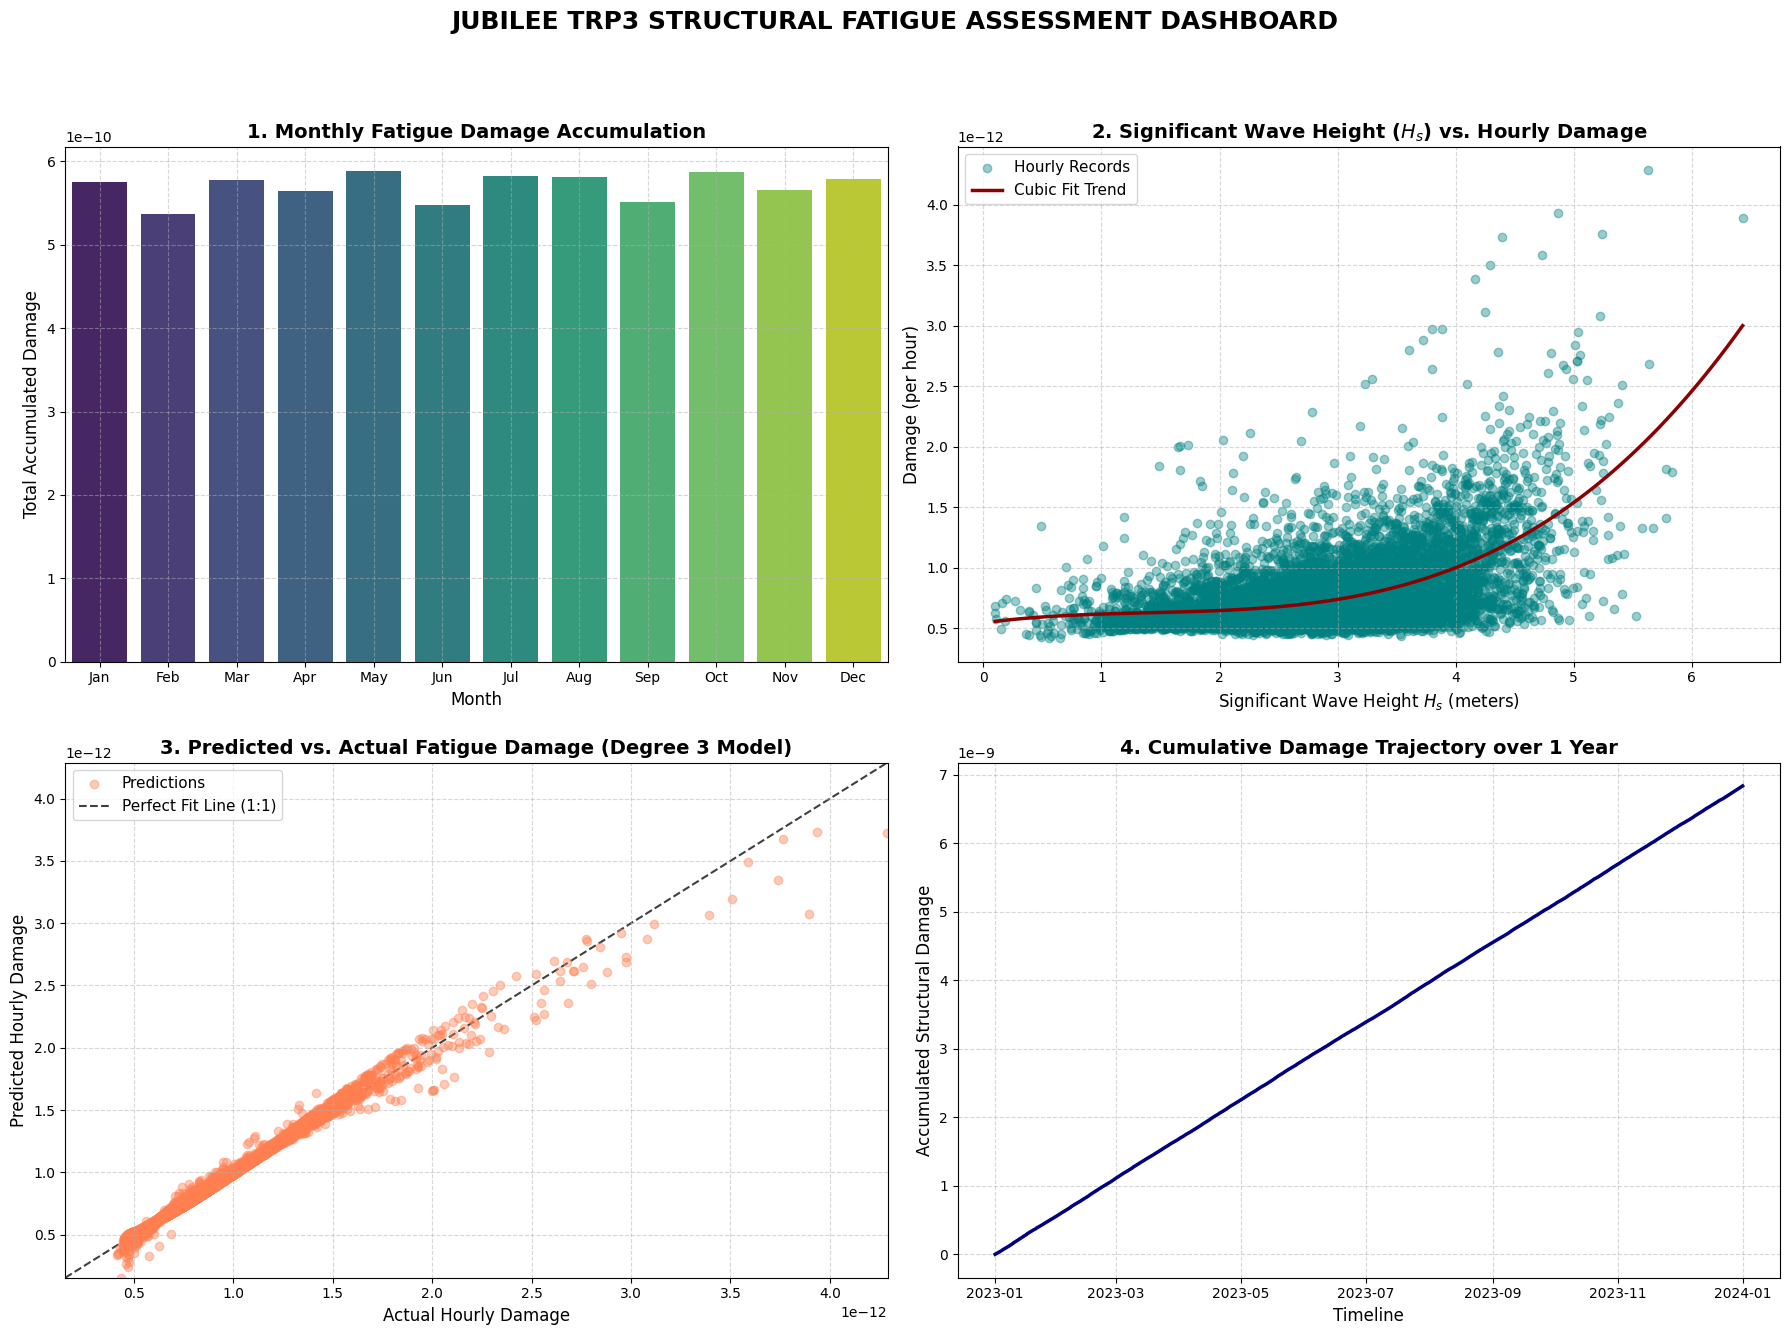

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare monthly accumulation data
df_full['Month_Name'] = df_full['Timestamp'].dt.strftime('%b')
monthly_dmg = df_full.groupby('Month_Name')['Hourly_Damage'].sum().reindex(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
).reset_index()

# Create a 2x2 grid for the Dashboard
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# --- Plot 1: Monthly Damage Accumulation ---
sns.barplot(x='Month_Name', y='Hourly_Damage', data=monthly_dmg, ax=axes[0, 0], palette='viridis', hue='Month_Name', legend=False)
axes[0, 0].set_title('1. Monthly Fatigue Damage Accumulation', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Month', fontsize=12)
axes[0, 0].set_ylabel('Total Accumulated Damage', fontsize=12)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Hs vs. Damage Scatter ---
axes[0, 1].scatter(df_full['Significant_Wave_Height_m'], df_full['Hourly_Damage'], color='teal', alpha=0.4, label='Hourly Records')
# Fit a trendline to illustrate relationship
p_fit = np.polyfit(df_full['Significant_Wave_Height_m'], df_full['Hourly_Damage'], 3)
line_x = np.linspace(df_full['Significant_Wave_Height_m'].min(), df_full['Significant_Wave_Height_m'].max(), 100)
line_y = np.polyval(p_fit, line_x)
axes[0, 1].plot(line_x, line_y, color='darkred', lw=2.5, linestyle='-', label='Cubic Fit Trend')
axes[0, 1].set_title('2. Significant Wave Height ($H_s$) vs. Hourly Damage', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Significant Wave Height $H_s$ (meters)', fontsize=12)
axes[0, 1].set_ylabel('Damage (per hour)', fontsize=12)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)
axes[0, 1].legend(fontsize=11)

# --- Plot 3: Predicted vs. Actual Damage (Parity Plot) ---
axes[1, 0].scatter(y, y_pred_all, color='coral', alpha=0.4, label='Predictions')
lims = [min(y.min(), y_pred_all.min()), max(y.max(), y_pred_all.max())]
axes[1, 0].plot(lims, lims, 'k--', alpha=0.75, zorder=0, label='Perfect Fit Line (1:1)')
axes[1, 0].set_title('3. Predicted vs. Actual Fatigue Damage (Degree 3 Model)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Actual Hourly Damage', fontsize=12)
axes[1, 0].set_ylabel('Predicted Hourly Damage', fontsize=12)
axes[1, 0].set_xlim(lims)
axes[1, 0].set_ylim(lims)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)
axes[1, 0].legend(fontsize=11)

# --- Plot 4: Cumulative Damage Trajectory ---
axes[1, 1].plot(df_full['Timestamp'], df_full['Cumulative_Damage'], color='navy', lw=2.5)
axes[1, 1].set_title('4. Cumulative Damage Trajectory over 1 Year', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Timeline', fontsize=12)
axes[1, 1].set_ylabel('Accumulated Structural Damage', fontsize=12)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('JUBILEE TRP3 STRUCTURAL FATIGUE ASSESSMENT DASHBOARD', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()